In [1]:
class EaterEnvironment:
    def __init__(self, mover_policy, grid_size=7, g1_state=37, g2_state=49, initial_bananas_g1=100, initial_bananas_g2=100):
        self.mover_policy = mover_policy
        self.grid_size = grid_size
        self.g1 = self.state_to_position(g1_state)
        self.g2 = self.state_to_position(g2_state)
        self.bananas_g1 = initial_bananas_g1
        self.bananas_g2 = initial_bananas_g2
        self.actions = [
            (1, 0), (0, 1), (0.5, 0.5), (0.2, 0.8), (0.6, 0.4),
            (0.8, 0.2), (0.4, 0.6), (0.7, 0.3), (0.3, 0.7)
        ]

    def state_to_position(self, state):
        x = (state - 1) % self.grid_size
        y = (state - 1) // self.grid_size
        return (x, y)

    def calculate_distance(self, pos1, pos2):
        return abs(pos1[0] - pos2[0]) + abs(pos1[1] - pos2[1])

    def calculate_reward(self, distance_to_g1, distance_to_g2, action_index):
      if distance_to_g1 + distance_to_g2 == 0:
          return 0  # Avoid division by zero, although unlikely in practical scenarios

      # Ratio of how much should ideally be consumed from g1 based on its relative closeness
      ideal_g1_ratio = distance_to_g2 / (distance_to_g1 + distance_to_g2)
      ideal_g2_ratio = 1 - ideal_g1_ratio  # Complement of g1 ratio for g2

      # Actions defined with their consumption ratios from g1 and g2
      action_ratios = {
          0: (1.0, 0.0),  # All from g1
          1: (0.0, 1.0),  # All from g2
          2: (0.5, 0.5),  # Equally from both
          3: (0.2, 0.8),  # Mainly from g2
          4: (0.6, 0.4),  # Mainly from g1
          5: (0.8, 0.2),  # Mainly from g1
          6: (0.4, 0.6),  # Mainly from g2
          7: (0.7, 0.3),  # Mainly from g1
          8: (0.3, 0.7)   # Mainly from g2
      }

      actual_g1_ratio, actual_g2_ratio = action_ratios[action_index]

      # Calculate the absolute differences between actual ratios and ideal ratios
      diff_g1 = abs(actual_g1_ratio - ideal_g1_ratio)
      diff_g2 = abs(actual_g2_ratio - ideal_g2_ratio)

      # Evaluate the reward based on how well the actual ratios align with the ideal ratios
      reward = 1 - (diff_g1 + diff_g2)  # Reward is higher when the differences are smaller

      # Scale the reward to fit into specific reward levels you mentioned
      if reward > 0.95:
          return 1
      elif reward > 0.9:
          return 0.8
      elif reward > 0.85:
          return 0.7
      elif reward > 0.8:
          return 0.6
      elif reward > 0.75:
          return 0.4
      elif reward > 0.7:
          return 0.3
      elif reward > 0.65:
          return 0.2
      elif reward > 0.6:
          return 0
      else:
          return -1





    def step(self, eater_state, action_index):
            mover_current_state, _ = eater_state  # Current mover position and the last action (not needed here)
            mover_next_action = self.mover_policy(mover_current_state)  # Determine the next action from the current state
            mover_position = self.state_to_position(mover_current_state)
            mover_next_position = self.update_position(mover_position, mover_next_action)
            next_mover_state = self.position_to_state(mover_next_position)

            # Determine the next action the mover will take from the new position
            next_mover_action = self.mover_policy(next_mover_state)

            distance_to_g1 = self.calculate_distance(mover_next_position, self.g1)
            distance_to_g2 = self.calculate_distance(mover_next_position, self.g2)
            goal1_consume, goal2_consume = self.actions[action_index]
            self.bananas_g1 -=   goal1_consume
            self.bananas_g2 -= goal2_consume

            reward = self.calculate_reward( distance_to_g1, distance_to_g2, action_index)

            # Next state now correctly includes the next mover position and the next action
            next_state = (next_mover_state, next_mover_action)
            return next_state, reward

    def update_position(self, position, action):
        x, y = position
        if action == 0 and y < self.grid_size - 1:
            y += 1
        elif action == 1 and y > 0:
            y -= 1
        elif action == 2 and x > 0:
            x -= 1
        elif action == 3 and x < self.grid_size - 1:
            x += 1
        return (x, y)

    def position_to_state(self, position):
        x, y = position
        return y * self.grid_size + x + 1


In [2]:
def mover_policy(current_state):
    goal_position = (6, 6)  # True goal is at state 49 (position (6, 6))
    current_position = ((current_state - 1) % 7, (current_state - 1) // 7)
    dx = goal_position[0] - current_position[0]
    dy = goal_position[1] - current_position[1]
    if abs(dx) > abs(dy):
        return 3 if dx > 0 else 2
    elif dy != 0:
        return 0 if dy > 0 else 1
    return 4


In [4]:
import random
env = EaterEnvironment(mover_policy)
next_state = (1,0)
for i in range(10):
  action = random.choice(range(len(env.actions)))
  next_state, reward = env.step(next_state, action)
  print(next_state,action,reward)

(8, 3) 7 1
(9, 0) 1 -1
(16, 3) 1 -1
(17, 0) 1 -1
(24, 3) 4 0.4
(25, 0) 7 0.4
(32, 3) 3 -1
(33, 0) 4 0.4
(40, 3) 7 0
(41, 0) 2 0.2


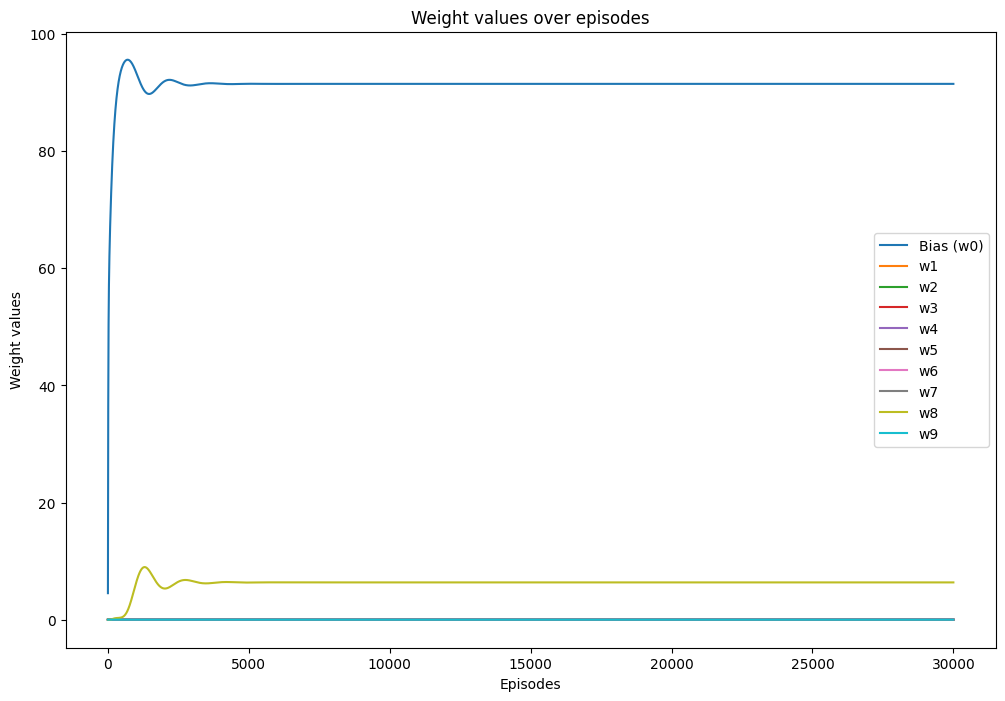

Final weights after training: [ 9.15070494e+01 -1.00000000e-02 -1.04516896e-02 -8.69550996e-04
 -1.12624213e-02 -3.90673447e-04 -3.01865579e-03 -1.70365691e-02
  6.35656711e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Re-instantiate the environment with the provided mover policy
env = EaterEnvironment(mover_policy)

# Parameters
alpha = 0.01  # Step size
gamma = 0.99  # Discount factor
total_episodes = 30000  # Reduced number for manageable simulations
T = 500  # Length of an episode

# The feature dimension is (grid size * grid size) * number of actions + 1 (for the bias term)
feature_dim = 1 + env.grid_size ** 2 * len(env.actions)
w = np.zeros(feature_dim)  # Initialize weights

# Feature vector representation that encodes mover position and eater action
def feature_vector(state, eater_action):
    features = np.zeros(feature_dim)
    features[0] = 1  # Bias term
    mover_position = env.position_to_state(env.state_to_position(state[0])) - 1
    action_offset = mover_position * len(env.actions) + eater_action
    features[1 + action_offset] = 1  # One-hot encode mover position and eater action
    return features

# Value function estimate using linear function approximation
def v_hat(state, eater_action, w):
    return np.dot(w, feature_vector(state, eater_action))

# Policy function for the eater: chooses action based on current mover position
def policy(state):
    return np.argmax([v_hat(state, action, w) for action in range(len(env.actions))])

# Semi-gradient TD learning algorithm
def semi_gradient_td(w, alpha, gamma, total_episodes, T):
    w_history = np.zeros((total_episodes, len(w)))  # Store history of weights for plotting
    for episode in range(total_episodes):
        state = (1, 0)  # Start with an initial state
        for t in range(T):
            action = policy(state)
            next_state, reward = env.step(state, action)
            next_action = policy(next_state)
            grad_v = feature_vector(state, action)
            td_target = reward + gamma * v_hat(next_state, next_action, w)
            td_error = td_target - v_hat(state, action, w)
            w += alpha * td_error * grad_v
            state = next_state
        w_history[episode] = w

    return w, w_history

# Run the learning algorithm
final_weights, weights_history = semi_gradient_td(w, alpha, gamma, total_episodes, T)

# Plotting the evolution of weights
plt.figure(figsize=(12, 8))
plt.plot(weights_history[:, 0], label='Bias (w0)')
for i in range(1, min(10, len(w))):
    plt.plot(weights_history[:, i], label=f'w{i}')
plt.xlabel('Episodes')
plt.ylabel('Weight values')
plt.title('Weight values over episodes')
plt.legend()
plt.show()

# Print the final weights
print("Final weights after training:", final_weights)